# The second SAGD phase: between graph split and full separation

With the MST connectivity fallback, the SAGD matrix of the bimodal Gaussian at **D = 1024** (most
clearly at N = 4000) has three blocks rather than two: the noise stage, then an intermediate block
from the moment the kNN graph splits (`t ≈ 2.9`) to about `t ≈ 1.5`, and only then the strongly
changing tail toward `t = 0`. The question is what property of the CTD distribution makes the
middle block. In Euclidean terms nothing special happens there: the gap between within- and
between-cluster distances grows smoothly and monotonically as `t → 0`.

**Short answer.** The middle block is not a geometric regime of the samples. It comes from three
facts about the CTD distribution, all checked below:

1. **The within-cluster CTD distribution does not move.** In raw (unnormalized) log-CTD it is the
   same from `t = 10` to `t = 0`: within a cluster the graph is a kNN graph on isotropic noise, and
   its commute times follow the degree law of `ctd_investigation.ipynb`, which knows nothing about
   the other cluster.
2. **After the split, every between-cluster CTD goes through one edge.** With the MST fallback the
   two clusters are joined by one bridge of weight $w_b$, so the graph works like a resistor circuit
   in series:
   $\mathrm{CTD}_b / \mathrm{vol}(G) \approx R_{\text{in}} + 1/w_b$, with $R_{\text{in}} \approx 0.9$
   constant. All between-cluster pairs collapse to **one spike**, and its position depends only on
   $1/w_b = \exp(r_b^2 / 2\sigma^2)$, with $r_b$ the bridge's Euclidean length.
3. **Min-max normalization reduces the whole distribution to that spike's position.** The spike
   is the maximum, so it fixes the scale, and the stationary within-cluster half is squeezed by
   $1/(\log \mathrm{CTD}_b - \log \mathrm{CTD}_{\min})$. SAGD after the split is therefore, almost
   exactly, a 1-D distance in that one coordinate. A proxy built from four numbers per snapshot
   reproduces the matrix with correlation 0.9999.

The CTD gap does grow monotonically, like the Euclidean one. It is a monotone but very non-linear
function of a single edge length: a **step** when the cut drops from hundreds of edges to the
one bridge, a **plateau** while that bridge is still about kNN length ($r_b \approx \sigma$, so
$1/w_b \approx e^{1/2}$ is comparable to $R_{\text{in}}$), and **runaway growth**
$\log \mathrm{CTD}_b \approx r_b^2/2\sigma^2 \propto e^{-2t}$ once the cluster separation
$\Delta(t) = 2\mu\sqrt{D}\,e^{-t}$ exceeds the kernel width. The second phase is that plateau.
Its end is predicted at $\Delta(t_\times) = \sigma$, i.e. $t_\times = \ln(2\mu\sqrt{D}/\sigma) \approx 1.77$.

**Data.** `data/mst_raw_ctds/` (D = 1024, N = 1000) is the only run with `--keep_raw_ctds`, so its
CTDs can still be split into within- and between-cluster pairs. It was run with `--clipping`, the
`data/mst/` runs without it. Recomputing the unclipped normalization from the raw CTDs reproduces
`data/mst/.../D1024_N1000_T10/SAGD.jbl` to machine precision (section 1), so the raw run stands
in for the unclipped one. The N = 4000 run only has compressed CTDs; section 5 checks the same
mechanism there from quantiles and the `proj2d.jbl` cut data.

In [1]:
from pathlib import Path

import joblib
import numpy as np
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.spatial.distance import pdist
from scipy.stats import wasserstein_distance

from lib.distances import ctd_matrix
from lib.stats import normalize, compress_equal_frequency

DATA_ROOT = Path("../data")
EXP = "log_scale_and_shift_D256 1024 4096_n{n}"
D = 1024
MU = 4.0
T = 10
N_BINS = 5000

RAW_DIR = DATA_ROOT / "mst_raw_ctds" / EXP.format(n=1000) / f"D{D}_N1000_T{T}"
MST_DIRS = {n: DATA_ROOT / "mst" / EXP.format(n=n) / f"D{D}_N{n}_T{T}" for n in (1000, 4000)}
INJ_DIR = DATA_ROOT / "injected" / EXP.format(n=1000) / f"D{D}_N1000_T{T}"
MU_DIR = np.ones(D) / np.sqrt(D)
FIGS = Path("figs")


def separation(t):
    """Distance between the two cluster centres at time `t`."""
    return 2 * MU * np.sqrt(D) * np.exp(-t)

## Per-snapshot summary of the raw-CTD run

One pass over all 233 snapshots of the raw run. It reads `CTDs.jbl` (~1.6 GB), `history.jbl` and
`Ws.jbl` once and caches the result as `second_phase.jbl` next to them. Pairs are labelled
within/between by the sign of the projection on the mean-difference direction, the same rule as
`ou_model.classify`. Per snapshot it keeps:

* log1p-CTD statistics, separately for within- and between-cluster pairs (median, 1st/99th
  percentile), plus the global min/max and 5th/95th percentiles, which are the four anchors of the
  unclipped and clipped `log_scale_and_shift` normalizations;
* the graph cut: the number and total weight of between-cluster edges, $\mathrm{vol}(G)$ and the
  kernel width $\sigma$;
* Euclidean distances: mean length of within-/between-cluster kNN edges, and the mean over all
  within-/between-cluster pairs;
* the unclipped normalized CTDs, compressed to 5000 quantiles as the pipeline does, for
  recomputing the unclipped SAGD matrix.

In [2]:
def summarize_snapshot(t, ctd, points, W):
    labels = np.sign(points @ MU_DIR)
    iu, ju = np.triu_indices(len(points), k=1)
    between = labels[iu] != labels[ju]
    lc = np.log1p(ctd)
    ei, ej = np.triu(W, 1).nonzero()
    cross = labels[ei] != labels[ej]
    edge_len = np.linalg.norm(points[ei] - points[ej], axis=1)
    pair_len = pdist(points)
    return {
        "t": t,
        "lc_min": lc.min(), "lc_max": lc.max(),
        "lc_p5": np.percentile(lc, 5), "lc_p95": np.percentile(lc, 95),
        "lc_w_med": np.median(lc[~between]), "lc_b_med": np.median(lc[between]),
        "lc_w_p1": np.percentile(lc[~between], 1), "lc_w_p99": np.percentile(lc[~between], 99),
        "lc_b_p1": np.percentile(lc[between], 1), "lc_b_p99": np.percentile(lc[between], 99),
        "n_cut": int(cross.sum()), "cut_w": float(W[ei[cross], ej[cross]].sum()),
        "vol": float(W.sum()),
        "edge_w_len": edge_len[~cross].mean(),
        "edge_b_len": edge_len[cross].mean() if cross.any() else np.nan,
        "pair_w_len": pair_len[~between].mean(), "pair_b_len": pair_len[between].mean(),
        "norm_q": compress_equal_frequency(normalize(ctd, "log_scale_and_shift"), N_BINS),
    }


def sagd_matrix(quantiles, n_jobs=48):
    n = len(quantiles)
    pairs = [(i, j) for i in range(n) for j in range(i + 1, n)]
    dists = Parallel(n_jobs=n_jobs)(delayed(wasserstein_distance)(quantiles[i], quantiles[j])
                                    for i, j in pairs)
    S = np.zeros((n, n))
    for (i, j), v in zip(pairs, dists):
        S[i, j] = S[j, i] = v
    return S


def load_summary(run_dir):
    cache = run_dir / "second_phase.jbl"
    if cache.exists():
        return joblib.load(cache)
    graphs = joblib.load(run_dir / "Ws.jbl")
    ctds = joblib.load(run_dir / "CTDs.jbl")["CTDs"]
    hist = joblib.load(run_dir / "history.jbl")["history"]
    ts = np.asarray(graphs["ts"])
    rows = [summarize_snapshot(t, np.asarray(ctds[t]["ctds"]), np.asarray(hist[t], float), W)
            for t, W in zip(ts, graphs["Ws"])]
    summary = {key: np.array([r[key] for r in rows]) for key in rows[0] if key != "norm_q"}
    summary["sigma"] = np.asarray(graphs["sigma"], float)
    summary["sagd_noclip"] = sagd_matrix([r["norm_q"] for r in rows])
    joblib.dump(summary, cache, compress=3)
    return summary


raw = load_summary(RAW_DIR)
ts = raw["t"]
t_split = ts[np.argmax(raw["n_cut"] == 1)]
print(f"{len(ts)} snapshots; the cut is a single bridge from t = {t_split:.2f} onwards")

233 snapshots; the cut is a single bridge from t = 2.88 onwards


## 1. Clipping is why the raw-CTD and `mst` runs look different

`mst_raw_ctds` was run with `clipping: True`, the `data/mst/` runs with `clipping: False`;
everything else in `settings.log` is the same, and the graphs are identical. Renormalizing the raw
CTDs without clipping gives exactly the `mst` N = 1000 matrix, so from here on the raw run is used
to explain the unclipped matrices. Section 6 comes back to the clipped one.

All heatmaps are on the snapshot index axis, labelled with $t$, because the snapshots are not
equally spaced in time. They are clipped at their 95th percentile, and the DP breakpoints from each
run's `clusters.jbl` are drawn as white lines.

max |recomputed unclipped - mst N=1000| = 5.403663627667754e-16
DP breakpoints (t):
              mst N=4000: [2.94 2.88 2.82 1.65 0.99 0.78 0.54 0.42 0.24]
              mst N=1000: [2.94 2.88 1.44 1.14 0.96 0.75 0.63 0.51 0.21]
    raw (clipped) N=1000: [3.09 3.   2.97 2.94 2.88 1.74 1.29 0.99 0.63]


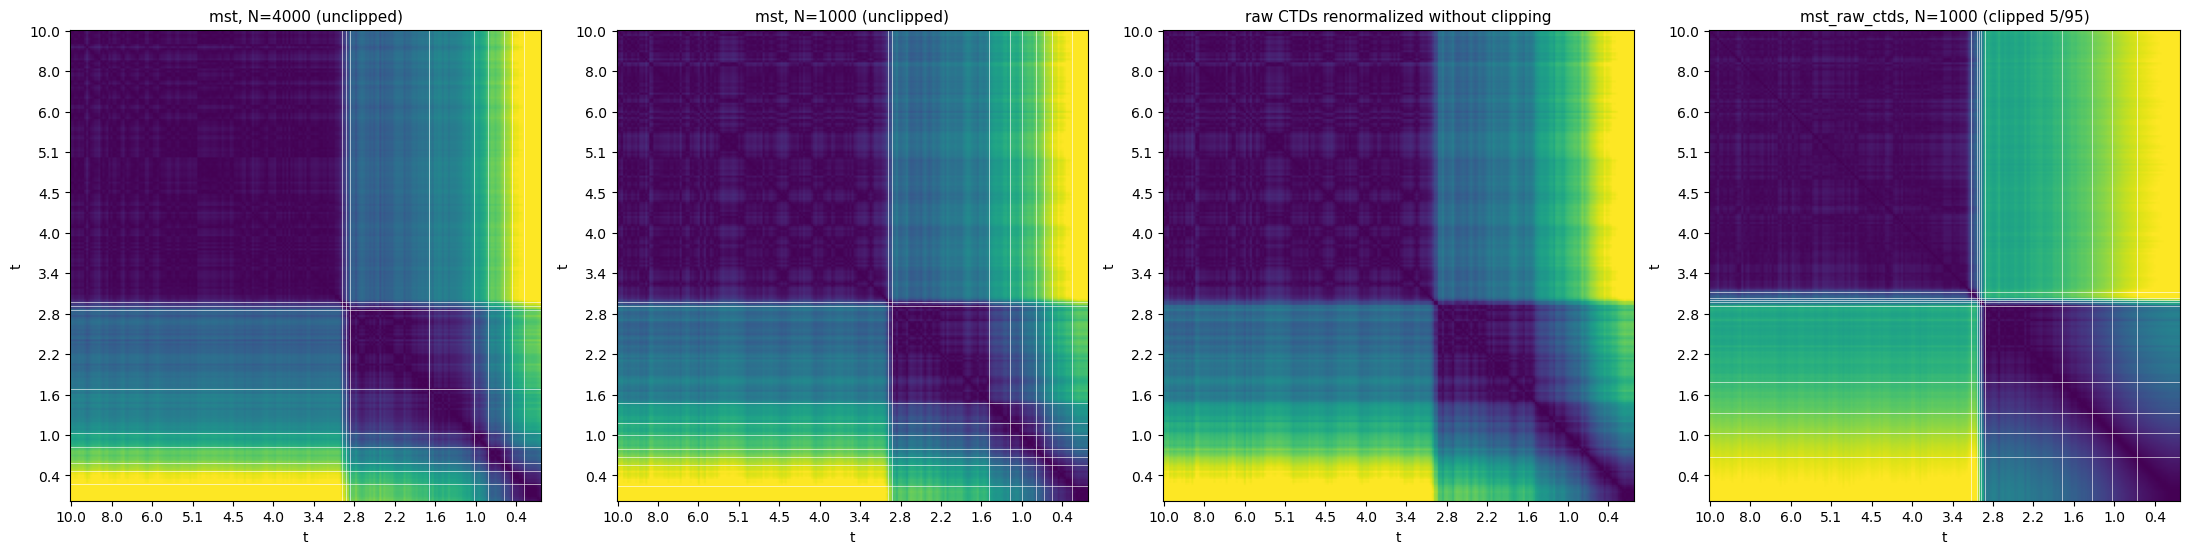

In [3]:
mst = {n: {"S": joblib.load(d / "SAGD.jbl"), "bp": np.asarray(joblib.load(d / "clusters.jbl"))}
       for n, d in MST_DIRS.items()}
raw_clipped = {"S": joblib.load(RAW_DIR / "SAGD.jbl"),
               "bp": np.asarray(joblib.load(RAW_DIR / "clusters.jbl"))}

print("max |recomputed unclipped - mst N=1000| =",
      np.abs(raw["sagd_noclip"] - mst[1000]["S"]).max())
print("DP breakpoints (t):")
for name, run in (("mst N=4000", mst[4000]), ("mst N=1000", mst[1000]),
                  ("raw (clipped) N=1000", raw_clipped)):
    print(f"  {name:>22}: {np.round(ts[run['bp']], 2)}")


def time_ticks(ax, ts, every=20):
    idx = np.arange(0, len(ts), every)
    ax.set_xticks(idx)
    ax.set_xticklabels(np.round(ts[idx], 1))
    ax.set_yticks(idx)
    ax.set_yticklabels(np.round(ts[idx], 1))
    ax.set_xlabel("t")
    ax.set_ylabel("t")


def draw_heatmap(ax, S, title, breakpoints=()):
    ax.imshow(S, cmap="viridis", vmax=np.nanpercentile(S, 95))
    for b in breakpoints:
        ax.axhline(b, color="white", lw=0.6, alpha=0.7)
        ax.axvline(b, color="white", lw=0.6, alpha=0.7)
    time_ticks(ax, ts)
    ax.set_title(title, fontsize=11)


fig, axes = plt.subplots(1, 4, figsize=(22, 5.6))
draw_heatmap(axes[0], mst[4000]["S"], "mst, N=4000 (unclipped)", mst[4000]["bp"])
draw_heatmap(axes[1], mst[1000]["S"], "mst, N=1000 (unclipped)", mst[1000]["bp"])
draw_heatmap(axes[2], raw["sagd_noclip"], "raw CTDs renormalized without clipping")
draw_heatmap(axes[3], raw_clipped["S"], "mst_raw_ctds, N=1000 (clipped 5/95)", raw_clipped["bp"])
fig.tight_layout()
fig.savefig(FIGS / "second_phase_heatmaps.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Euclidean gap vs. CTD gap over time

Left: Euclidean distances over all within- and between-cluster pairs (median and 1–99 % band).
The within-cluster distribution stays at $\approx\sqrt{2D}$ throughout. The between-cluster median
grows smoothly as $\approx\sqrt{2D + \Delta(t)^2}$, with $\Delta(t) = 2\mu\sqrt{D}e^{-t}$ the
distance between the cluster centres. Its band separates from the within-cluster one gradually,
with no feature at the split.

Right: log CTD, **before** normalization. The within-cluster distribution (median and 1–99 %
band) stays flat over all of $t \in [0, 10]$. The between-cluster distribution sits exactly on it
until the split, then within one snapshot leaves it as a narrow spike: its 1–99 % band is almost
invisible. The spike then hardly moves until $t \approx 1.7$ and afterwards takes off. So the
CTD gap is monotone too, but has a step-plateau-explosion profile that the Euclidean gap does not.

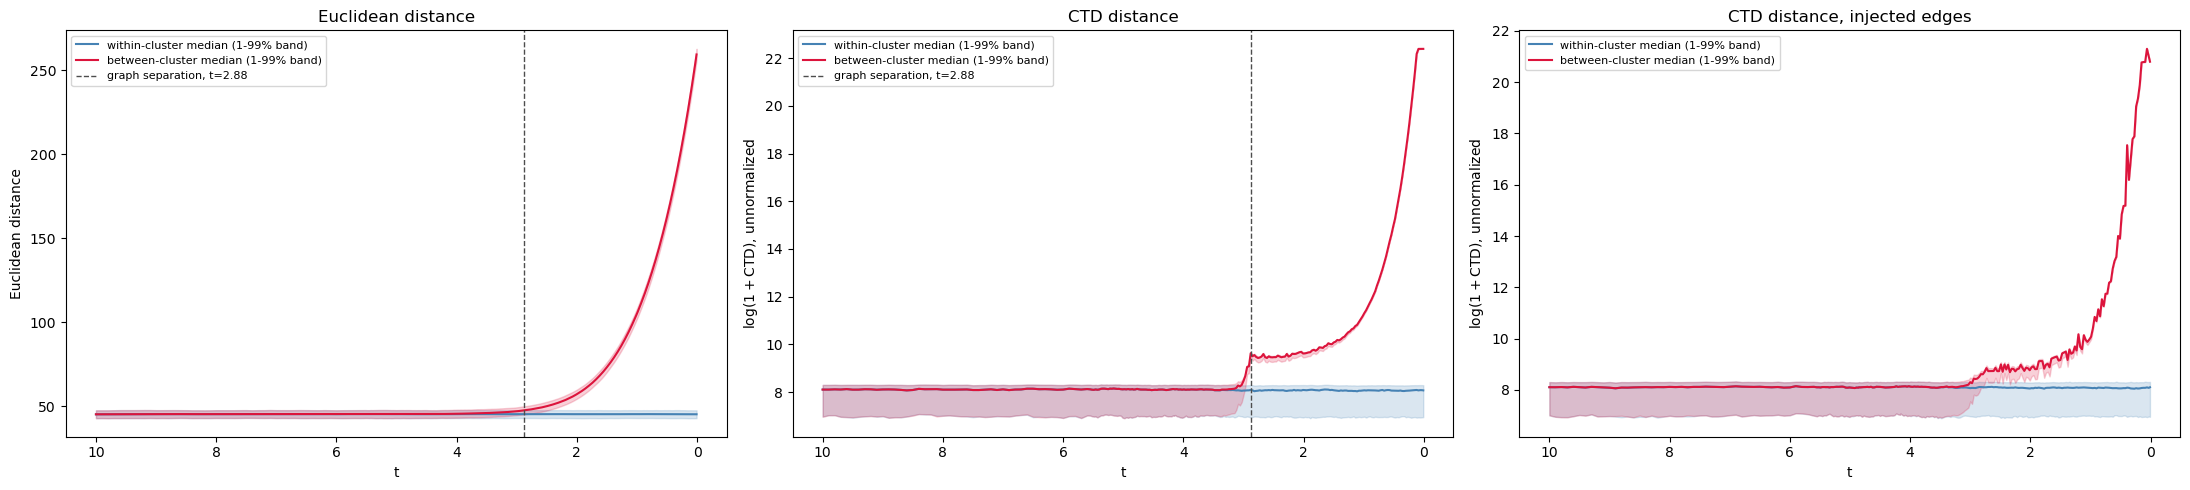

In [4]:
def mark_times(ax, lines):
    for t, style, label in lines:
        ax.axvline(t, color="0.3", ls=style, lw=1, label=label)


t_cross = np.log(2 * MU * np.sqrt(D) / np.median(raw["sigma"][ts <= t_split]))
markers = [(t_split, "--", f"graph separation, t={t_split:.2f}"),
           (t_cross, ":", rf"$\Delta(t)=\sigma$, t={t_cross:.2f}")]

def euclid_snapshot(points):
    labels = np.sign(points @ MU_DIR)
    iu, ju = np.triu_indices(len(points), k=1)
    between = labels[iu] != labels[ju]
    r = pdist(points)
    return {f"{side}_{stat}": f(r[mask])
            for side, mask in (("w", ~between), ("b", between))
            for stat, f in (("med", np.median),
                            ("p1", lambda x: np.percentile(x, 1)),
                            ("p99", lambda x: np.percentile(x, 99)))}


def load_euclid_summary(run_dir):
    cache = run_dir / "second_phase_euclid.jbl"
    if cache.exists():
        return joblib.load(cache)
    hist = joblib.load(run_dir / "history.jbl")["history"]
    rows = [euclid_snapshot(np.asarray(hist[t], float)) for t in ts]
    summary = {key: np.array([r[key] for r in rows]) for key in rows[0]}
    joblib.dump(summary, cache)
    return summary


def injected_snapshot(W, points):
    labels = np.sign(points @ MU_DIR)
    iu, ju = np.triu_indices(len(points), k=1)
    between = labels[iu] != labels[ju]
    lc = np.log1p(ctd_matrix(W)[iu, ju])
    ei, ej = np.triu(W, 1).nonzero()
    return {"w_med": np.median(lc[~between]), "b_med": np.median(lc[between]),
            "w_p1": np.percentile(lc[~between], 1), "w_p99": np.percentile(lc[~between], 99),
            "b_p1": np.percentile(lc[between], 1), "b_p99": np.percentile(lc[between], 99),
            "n_cut": int((labels[ei] != labels[ej]).sum())}


def load_injected_summary(run_dir, n_jobs=16):
    cache = run_dir / "second_phase_injected.jbl"
    if cache.exists():
        return joblib.load(cache)
    graphs = joblib.load(run_dir / "Ws.jbl")
    hist = joblib.load(run_dir / "history.jbl")["history"]
    snaps = np.asarray(graphs["ts"])
    rows = Parallel(n_jobs=n_jobs)(delayed(injected_snapshot)(W, np.asarray(hist[t], float))
                                   for t, W in zip(snaps, graphs["Ws"]))
    summary = {key: np.array([r[key] for r in rows]) for key in rows[0]}
    summary["t"] = snaps
    joblib.dump(summary, cache)
    return summary


euclid = load_euclid_summary(RAW_DIR)
injected = load_injected_summary(INJ_DIR)
assert np.allclose(injected["t"], ts)
split_marker = [markers[0]]

fig, axes = plt.subplots(1, 3, figsize=(22, 5))
ax = axes[0]
ax.fill_between(ts, euclid["w_p1"], euclid["w_p99"], color="steelblue", alpha=0.2)
ax.fill_between(ts, euclid["b_p1"], euclid["b_p99"], color="crimson", alpha=0.2)
ax.plot(ts, euclid["w_med"], color="steelblue", label="within-cluster median (1-99% band)")
ax.plot(ts, euclid["b_med"], color="crimson", label="between-cluster median (1-99% band)")
ax.set_ylabel("Euclidean distance")
ax.set_title("Euclidean distance")

ax = axes[1]
ax.fill_between(ts, raw["lc_w_p1"], raw["lc_w_p99"], color="steelblue", alpha=0.2)
ax.fill_between(ts, raw["lc_b_p1"], raw["lc_b_p99"], color="crimson", alpha=0.2)
ax.plot(ts, raw["lc_w_med"], color="steelblue", label="within-cluster median (1-99% band)")
ax.plot(ts, raw["lc_b_med"], color="crimson", label="between-cluster median (1-99% band)")
# ax.plot(ts, raw["lc_min"], color="0.5", lw=0.8, label="global min")
ax.set_ylabel(r"$\log(1 + \mathrm{CTD})$, unnormalized")
ax.set_title("CTD distance")

ax = axes[2]
ax.fill_between(ts, injected["w_p1"], injected["w_p99"], color="steelblue", alpha=0.2)
ax.fill_between(ts, injected["b_p1"], injected["b_p99"], color="crimson", alpha=0.2)
ax.plot(ts, injected["w_med"], color="steelblue", label="within-cluster median (1-99% band)")
ax.plot(ts, injected["b_med"], color="crimson", label="between-cluster median (1-99% band)")
ax.set_ylabel(r"$\log(1 + \mathrm{CTD})$, unnormalized")
ax.set_title("CTD distance, injected edges")

for ax in axes[:2]:
    mark_times(ax, split_marker)
for ax in axes:
    ax.invert_xaxis()
    ax.set_xlabel("t")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIGS / "second_phase_gaps.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. The between-cluster CTD is a series sum through the bridge

After the split the two clusters A and B are joined by a single edge $(a, b)$, so every walk
between them crosses it. For $i \in A$, $j \in B$ this makes the commute time additive. A walk
from $i$ to $j$ must visit $a$ and then $b$, so by the strong Markov property
$H(i,j) = H(i,a) + H(a,b) + H(b,j)$, and the same holds for the reverse trip. Hence, **exactly**,

$$\mathrm{CTD}(i, j) \;=\;
\underbrace{\mathrm{CTD}(i, a) + \mathrm{CTD}(b, j)}_{\mathrm{CTD}_{\text{in}}(i,j)}
\;+\; \underbrace{\frac{\mathrm{vol}(G)}{w_b}}_{\mathrm{CTD}_{\text{bridge}}},
\qquad w_b = \exp\!\left(-\frac{r_b^2}{2\sigma^2}\right).$$

$\mathrm{CTD}(a,b) = \mathrm{vol}(G)/w_b$ because the bridge's effective resistance is exactly
$1/w_b$. Equivalently, by Kac's lemma, $H(a,b) = (2W_A + w_b)/w_b$, and adding the reverse gives
$H(a,b) + H(b,a) = \mathrm{vol}(G)/w_b$. The weight $w_b$ is the pipeline's own Gaussian kernel on
the bridge length $r_b$: `connect_components` adds the bridge to the adjacency, and `compute_W`
weights it like any other edge, floored at `1e-6`.

$\mathrm{CTD}_{\text{bridge}}$ is the same for every between-cluster pair, so the median
between-cluster CTD is $\mathrm{CTD}_{\text{bridge}}$ plus the median of $\mathrm{CTD}_{\text{in}}$. The
figure checks this with nothing fitted: $\mathrm{CTD}_{\text{bridge}}$ is read directly off `W`, and
the empirical $\mathrm{CTD}_{\text{in}}$ is the between-cluster median minus
$\mathrm{CTD}_{\text{bridge}}$.

$\mathrm{CTD}_{\text{in}}$ consists of commute times inside the frozen clusters. By the degree law
it is $\approx \mathrm{vol}(G)\,(1/d_i + 1/d_a + 1/d_b + 1/d_j)$. That is four degree terms
against two for a within-cluster pair, which is why it sits above the within-cluster median. It
fluctuates because the bridge endpoints $a, b$, and so their degrees, change from snapshot to
snapshot. Below $t \approx 0.4$ the CTDs stored by the pipeline are no longer accurate enough
for the subtraction. `ctd_matrix` uses $1/\sqrt{\lambda + 10^{-10}}$, and with a single weak
bridge the Fiedler eigenvalue $\lambda_2$ scales with $w_b$, falling to $\sim 10^{-6}$–$10^{-9}$.
The offset then lowers $\mathrm{CTD}_b$ by about
$\mathrm{CTD}_{\text{bridge}} \cdot 10^{-10}/\lambda_2$. That is small relative to
$\mathrm{CTD}_b$, but larger than $\mathrm{CTD}_{\text{in}}$ once $\mathrm{CTD}_{\text{bridge}}$
reaches $10^7$–$10^9$; the stored values give a $\mathrm{CTD}_{\text{in}}$ that turns negative,
reaching $\sim -10^8$. The figure therefore recomputes the CTDs of every post-split snapshot from
`Ws.jbl` with the exact pseudo-inverse,
$\mathrm{CTD}(i,j) = \mathrm{vol}(G)\,(e_i - e_j)^\top L^{+}(e_i - e_j)$, where $L^+$ drops the
single zero eigenvalue and applies no offset. All three CTD curves come from that recomputation,
cached as `second_phase_exact.jbl`. The jitter in $\mathrm{CTD}_{\text{in}}$ over the last few snapshots
($t < 0.1$) is the float64 limit. There $w_b$ sits at the `1e-6` floor, so
$\mathrm{CTD}_{\text{bridge}} \approx 5 \times 10^9$, and recovering a $\sim 5 \times 10^3$
remainder needs a relative accuracy of $10^{-6}$. That is about what `eigh` achieves for an
eigenvalue $\lambda_2 \approx 4 \times 10^{-9}$ next to $\lVert L \rVert \sim 10^2$.

The plateau follows directly. While $r_b \approx \sigma$, $\mathrm{CTD}_{\text{bridge}} \approx
e^{1/2}\,\mathrm{vol}(G)$ is of the same order as $\mathrm{CTD}_{\text{in}}$, so their sum barely
moves. The bridge is the closest cross-cluster pair, and empirically
$r_b^2 \approx \rho^2 + \Delta(t)^2$ with $\rho \approx 38.5$ its transverse part. So it only
starts to stretch once the clusters are pulled apart by more than a kernel width. After that,
$\log \mathrm{CTD}_{\text{bridge}} \approx \log \mathrm{vol}(G) + \Delta(t)^2/2\sigma^2$ grows like
$e^{-2t}$ and the spike runs off. The crossover is at $\Delta(t_\times) = \sigma$:

$$t_\times = \ln\frac{2\mu\sqrt{D}}{\sigma} \approx 1.77 \quad (D=1024,\ \mu=4,\ \sigma\approx 43.6).$$

Since $\sigma \approx \sqrt{2D}$ in this regime, $t_\times \approx \ln(\sqrt{2}\,\mu)$ is nearly
independent of $D$.

**The figure.** The top panel shows the CTD decomposition and the bottom panel the unclipped SAGD
matrix of the same run, both cropped to $t \le 3.5$ (the matrix's colour scale is set on that
block); the two share the snapshot axis, labelled with $t$ (the snapshots are
not equally spaced in $t$). Before the split there is no bridge, so the two medians come from the
stored CTDs, where the eigenvalue offset is negligible. After the split all three CTD curves come
from the exact recomputation. Two lines are drawn on both panels: the graph separation, and the
onset of the third phase $t^*_{\mathrm{SAGD}}$ from `find_third_phase_onset` (the last crossing
of the min-max-scaled mean and std of the normalized CTDs). At $t^*_{\mathrm{SAGD}}$ the bridge term already
dominates: $\mathrm{CTD}_{\text{bridge}}$ is about 4× $\mathrm{CTD}_{\text{in}}$.

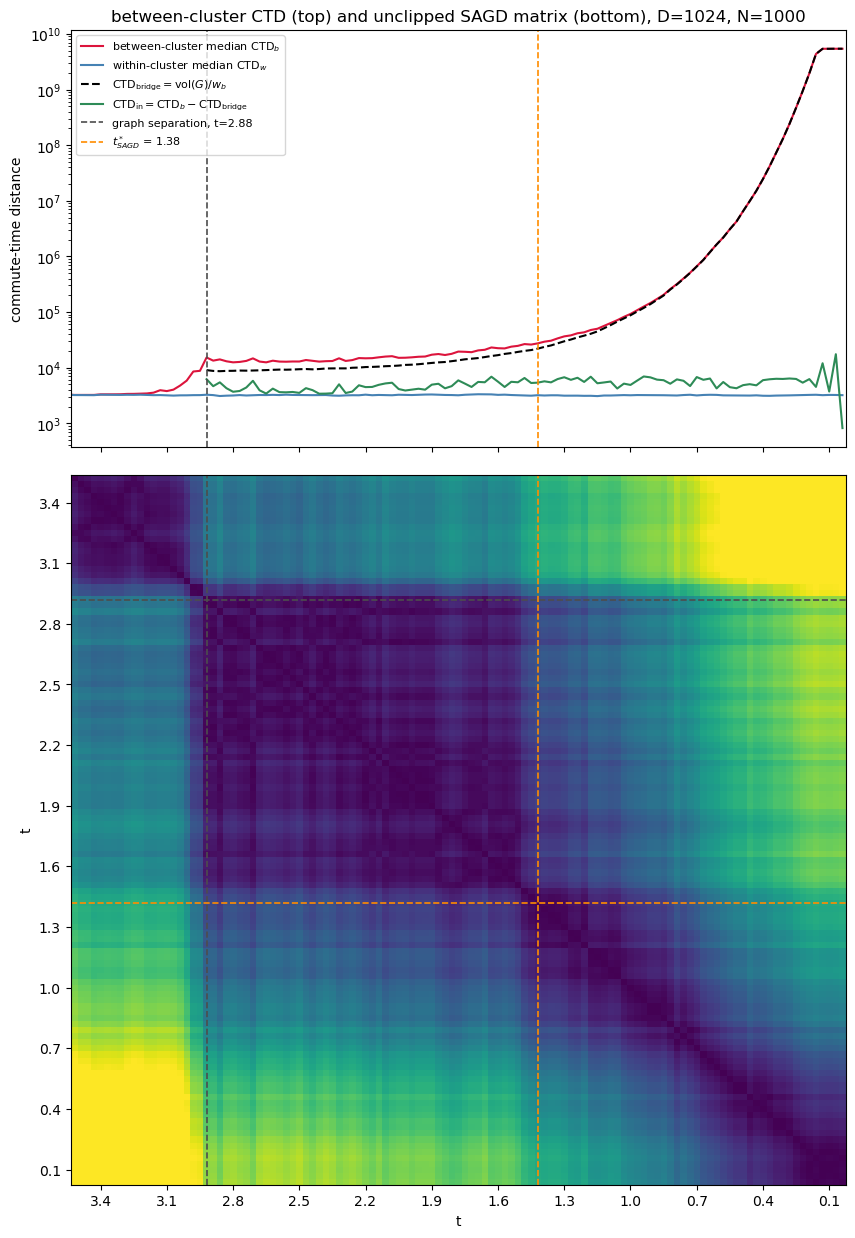

CTD_in over the whole post-split range: median 5154, range 818-17434;  within-cluster median CTD_w 3200
stored (offset) CTDs: CTD_in min -1.32e+08;  max |exact - stored| relative to CTD_b: 2.43e-02


In [5]:
def exact_ctd(W):
    vol = W.sum()
    lam, U = np.linalg.eigh(np.diag(W.sum(1)) - W)
    L_pinv = (U[:, 1:] / lam[1:]) @ U[:, 1:].T
    diag = np.diag(L_pinv)
    return vol * (diag[:, None] + diag[None] - 2 * L_pinv)


def load_exact_medians(run_dir, snaps):
    cache = run_dir / "second_phase_exact.jbl"
    if cache.exists():
        stored = joblib.load(cache)
        if np.allclose(stored["t"], snaps):
            return stored
    graphs = joblib.load(run_dir / "Ws.jbl")
    hist = joblib.load(run_dir / "history.jbl")["history"]
    index = {t: i for i, t in enumerate(np.asarray(graphs["ts"]))}
    ctd_b, ctd_w = [], []
    for t in snaps:
        labels = np.sign(np.asarray(hist[t], float) @ MU_DIR)
        C = exact_ctd(graphs["Ws"][index[t]])
        iu, ju = np.triu_indices(len(labels), k=1)
        between = labels[iu] != labels[ju]
        ctd_b.append(np.median(C[iu, ju][between]))
        ctd_w.append(np.median(C[iu, ju][~between]))
    stored = {"t": np.asarray(snaps), "ctd_b": np.array(ctd_b), "ctd_w": np.array(ctd_w)}
    joblib.dump(stored, cache)
    return stored


post = raw["n_cut"] == 1
ctd_b_over_vol = np.expm1(raw["lc_b_med"]) / raw["vol"]
inv_w = 1.0 / raw["cut_w"]

exact = load_exact_medians(RAW_DIR, ts[post])
t_post = ts[post]
ctd_bridge = (raw["vol"] / raw["cut_w"])[post]
ctd_in = exact["ctd_b"] - ctd_bridge

from lib.ou_model import find_third_phase_onset

idx = np.arange(len(ts))
ctd_b_all = np.expm1(raw["lc_b_med"])
ctd_w_all = np.expm1(raw["lc_w_med"])
ctd_b_all[post] = exact["ctd_b"]
ctd_w_all[post] = exact["ctd_w"]
t_star = find_third_phase_onset(joblib.load(MST_DIRS[1000] / "CTDs.jbl")["CTDs"], ts)
i_split, i_star = int(np.argmin(np.abs(ts - t_split))), int(np.argmin(np.abs(ts - t_star)))
phase_lines = [(i_split, "0.3", f"graph separation, t={t_split:.2f}"),
               (i_star, "darkorange", rf"$t^*_{{SAGD}}$ = {t_star:.2f}")]

fig, (ax, ax_hm) = plt.subplots(2, 1, figsize=(10, 15), sharex=True,
                                gridspec_kw={"height_ratios": [1, 1.7], "hspace": 0.05})
ax.plot(idx, ctd_b_all, color="crimson", label=r"between-cluster median $\mathrm{CTD}_b$")
ax.plot(idx, ctd_w_all, color="steelblue", label=r"within-cluster median $\mathrm{CTD}_w$")
ax.plot(idx[post], ctd_bridge, color="black", ls="--",
        label=r"$\mathrm{CTD}_{\mathrm{bridge}} = \mathrm{vol}(G) / w_b$")
ax.plot(idx[post], ctd_in, color="seagreen",
        label=r"$\mathrm{CTD}_{\mathrm{in}} = \mathrm{CTD}_b - \mathrm{CTD}_{\mathrm{bridge}}$")
for i, colour, label in phase_lines:
    ax.axvline(i, color=colour, ls="--", lw=1.2, label=label)
ax.set_yscale("log")
ax.set_ylabel("commute-time distance")
ax.set_title("between-cluster CTD (top) and unclipped SAGD matrix (bottom), D=1024, N=1000")
ax.legend(fontsize=8, loc="upper left")

S = raw["sagd_noclip"]
k0 = int(np.argmax(ts <= 3.5))
ax_hm.imshow(S, cmap="viridis", vmax=np.percentile(S[k0:, k0:], 95), aspect="auto")
for i, colour, _ in phase_lines:
    ax_hm.axvline(i, color=colour, ls="--", lw=1.2)
    ax_hm.axhline(i, color=colour, ls="--", lw=1.2)
time_ticks(ax_hm, ts, every=10)
ax_hm.set_xlim(k0 - 0.5, len(ts) - 0.5)
ax_hm.set_ylim(len(ts) - 0.5, k0 - 0.5)
fig.savefig(FIGS / "second_phase_bridge.png", dpi=150, bbox_inches="tight")
plt.show()

stored_in = (np.expm1(raw["lc_b_med"]) - raw["vol"] / raw["cut_w"])[post]
print(f"CTD_in over the whole post-split range: median {np.median(ctd_in):.0f}, "
      f"range {ctd_in.min():.0f}-{ctd_in.max():.0f};  within-cluster median CTD_w {np.median(exact['ctd_w']):.0f}")
print(f"stored (offset) CTDs: CTD_in min {stored_in.min():.3g};  "
      f"max |exact - stored| relative to CTD_b: {np.max(np.abs(stored_in - ctd_in) / exact['ctd_b']):.2e}")

## 4. Normalization turns SAGD into a 1-D distance

`log_scale_and_shift` without clipping maps $\ell = \log(1 + \mathrm{CTD})$ to
$(\ell - m_t)/(M_t - m_t)$, with $m_t, M_t$ the snapshot's min and max. After the split the
distribution is two halves of equal mass. The between half is a spike at $M_t$, which always maps
to $\approx 1$. The within half is a fixed distribution whose image is squeezed toward 0 by the
factor $1/(M_t - m_t)$. Write $p^w_t$ and $p^b_t$ for the normalized medians of the two halves.
The 1-D Wasserstein distance then reduces to

$$\mathrm{SAGD}(s, t) \;\approx\; \tfrac12\,\lvert p^w_s - p^w_t \rvert + \tfrac12\,\lvert p^b_s - p^b_t \rvert,
\qquad p^w_t \approx \frac{\ell^w - m}{M_t - m},\ \ p^b_t \approx 1,$$

so after the split every snapshot is a single point $p^w_t$, which depends only on the bridge
spike $M_t$. The proxy below uses just four numbers per snapshot (two medians, the min and the
max). The second phase is the stretch where $p^w_t$ stays flat because $M_t$ is on its plateau, and
the DP breakpoints sit where $p^w_t$ starts to move again.

The same proxy explains the checkerboard texture of the noise block in the unclipped matrices.
$m_t$ is the CTD of a single pair, and it jitters by ±0.5 from snapshot to snapshot (grey line in
section 2). With no clipping, that jitter rescales the whole distribution.

corr(proxy, SAGD): all snapshots 0.9901, after the split 0.99992


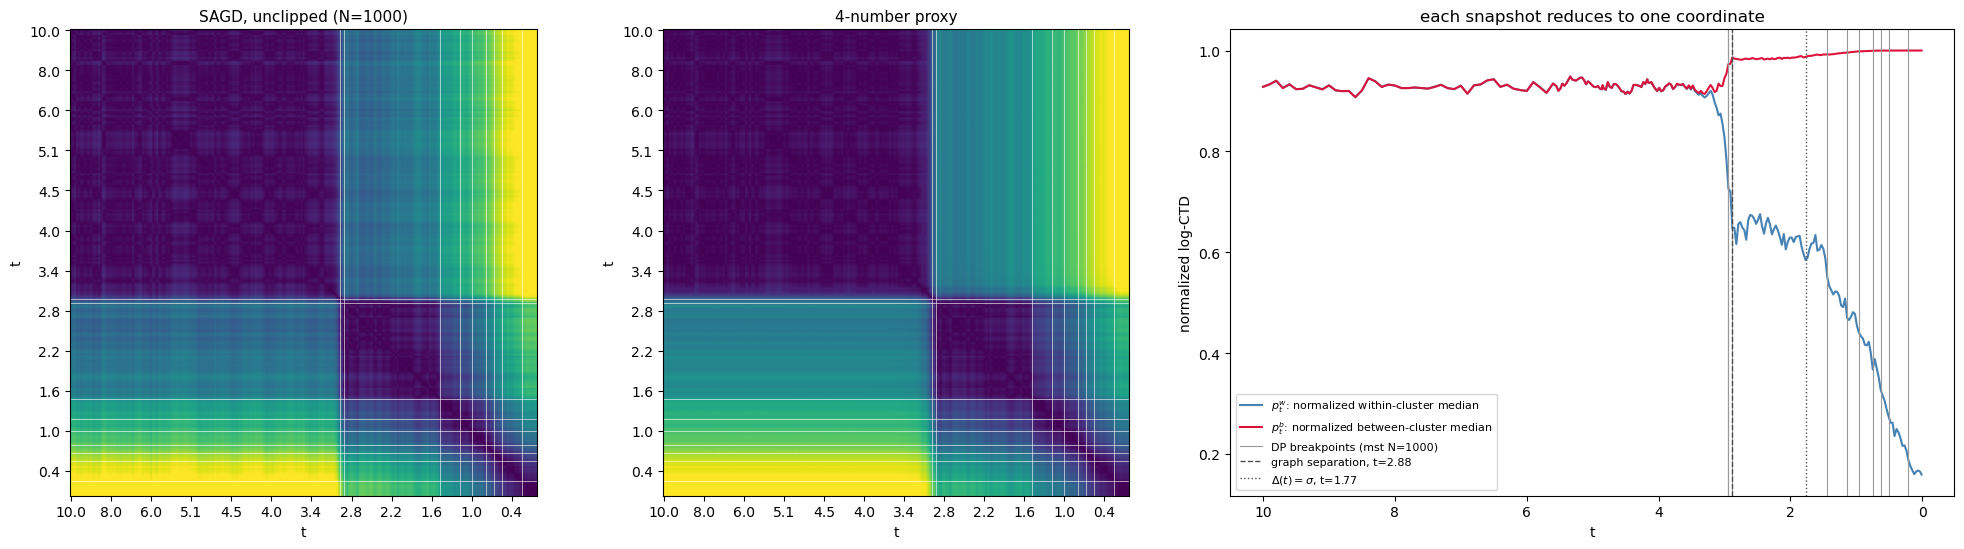

In [6]:
def proxy_sagd(lw, lb, m, M):
    pw = (lw - m) / (M - m)
    pb = (lb - m) / (M - m)
    return 0.5 * np.abs(pw[:, None] - pw[None]) + 0.5 * np.abs(pb[:, None] - pb[None]), pw, pb


def compare(S, P, mask):
    sub = np.ix_(mask, mask)
    return np.corrcoef(S[sub].ravel(), P[sub].ravel())[0, 1]


P_raw, pw_raw, pb_raw = proxy_sagd(raw["lc_w_med"], raw["lc_b_med"], raw["lc_min"], raw["lc_max"])
S_raw = raw["sagd_noclip"]
print(f"corr(proxy, SAGD): all snapshots {compare(S_raw, P_raw, np.ones_like(post)):.4f}, "
      f"after the split {compare(S_raw, P_raw, post):.5f}")

fig, axes = plt.subplots(1, 3, figsize=(20, 5.6), gridspec_kw={"width_ratios": [1, 1, 1.4]})
draw_heatmap(axes[0], S_raw, "SAGD, unclipped (N=1000)", mst[1000]["bp"])
draw_heatmap(axes[1], P_raw, "4-number proxy", mst[1000]["bp"])
ax = axes[2]
ax.plot(ts, pw_raw, color="steelblue", label=r"$p^w_t$: normalized within-cluster median")
ax.plot(ts, pb_raw, color="crimson", label=r"$p^b_t$: normalized between-cluster median")
for b in mst[1000]["bp"]:
    ax.axvline(ts[b], color="0.6", lw=0.8)
ax.axvline(ts[mst[1000]["bp"][0]], color="0.6", lw=0.8, label="DP breakpoints (mst N=1000)")
mark_times(ax, markers)
ax.invert_xaxis()
ax.set_xlabel("t")
ax.set_ylabel("normalized log-CTD")
ax.set_title("each snapshot reduces to one coordinate")
ax.legend(fontsize=8, loc="lower left")
fig.tight_layout()
fig.savefig(FIGS / "second_phase_proxy.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. The same mechanism at N = 4000

The N = 4000 run stores only 5000 equal-frequency quantiles per snapshot, so pairs cannot be
labelled. After the split, though, the two halves do not overlap and each holds 50% of the pairs
(49.9%, to be precise). So the within-cluster median is the 25% quantile and the between-cluster
median the 75% one, and the stored quantile grid still has the exact min and max. The bridge
weight comes from the cached `proj2d.jbl` (between-cluster edges per snapshot), so the 3.3 GB
`history.jbl` is not needed.

Left: the same unnormalized picture as section 2. Within stays flat, and the between spike steps,
plateaus and runs off. Middle and right: the proxy against the stored SAGD. The pre-split rows are
not reproduced here, because there the quartiles are not the within/between medians. That does
not matter, since the question is the post-split structure.

N=4000: split at t = 2.82; corr(proxy, SAGD) after the split 0.99997
bridge length / sigma at split 1.02, at t~1.7 1.36, at t~1.0 2.30


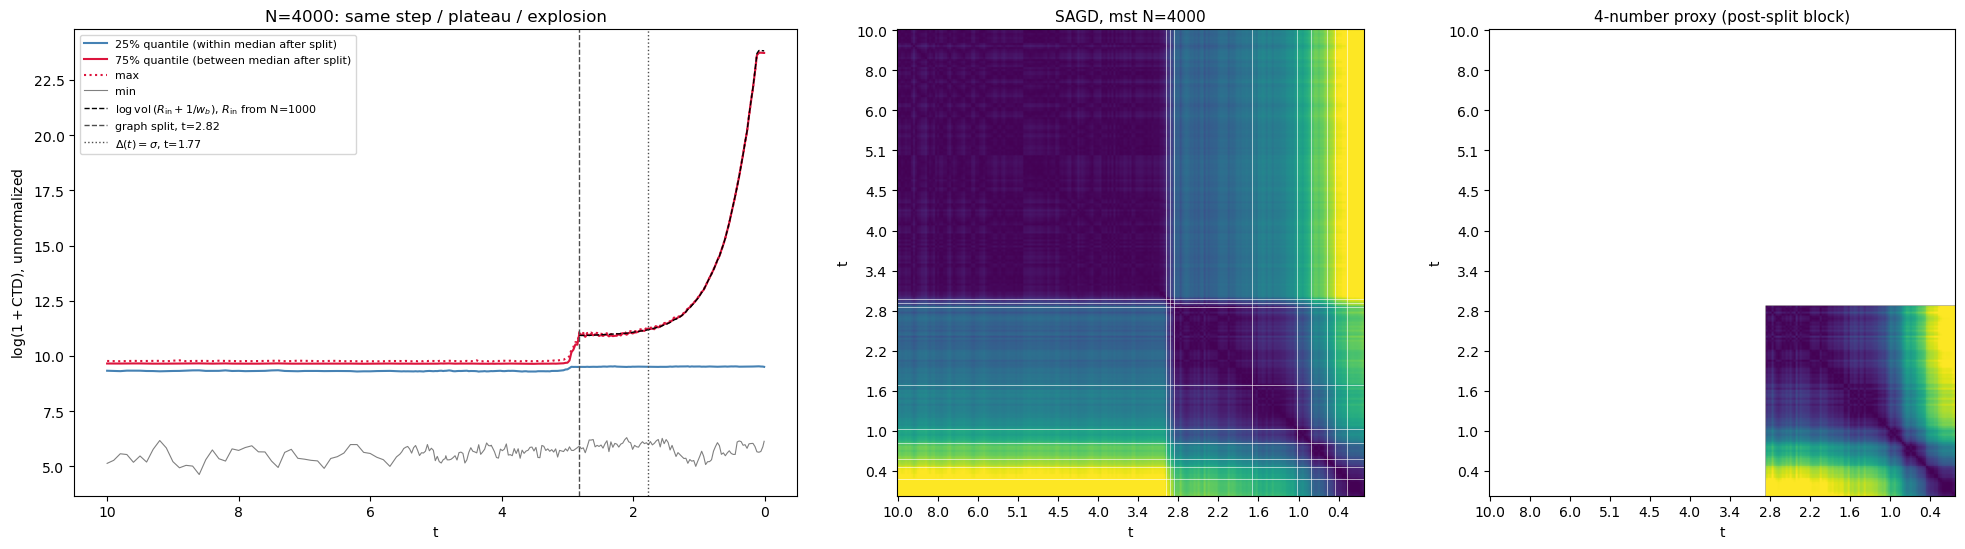

In [7]:
def quantile_summary(run_dir):
    stored = joblib.load(run_dir / "CTDs.jbl")
    snaps = np.asarray(stored["params"]["ts"])
    q = np.log1p(np.stack([np.asarray(stored["CTDs"][t]["ctds"]) for t in snaps]))
    n = q.shape[1]
    proj = joblib.load(run_dir / "proj2d.jbl")["proj"]
    return {
        "t": snaps,
        "lc_min": q[:, 0], "lc_max": q[:, -1],
        "lc_q25": q[:, n // 4], "lc_q75": q[:, 3 * n // 4],
        "n_cut": np.array([proj[t]["edges"].shape[1] for t in snaps]),
        "cut_w": np.array([proj[t]["cut"] for t in snaps]),
        "vol": np.array([2 * proj[t]["weight"] for t in snaps]),
    }


big = quantile_summary(MST_DIRS[4000])
assert np.allclose(big["t"], ts)
post_big = big["n_cut"] == 1
t_split_big = ts[np.argmax(post_big)]
P_big, pw_big, _ = proxy_sagd(big["lc_q25"], big["lc_q75"], big["lc_min"], big["lc_max"])
S_big = mst[4000]["S"]
print(f"N=4000: split at t = {t_split_big:.2f}; corr(proxy, SAGD) after the split "
      f"{compare(S_big, P_big, post_big):.5f}")
r_over_sigma = np.sqrt(2 * np.log(1 / big["cut_w"][post_big]))
print(f"bridge length / sigma at split {r_over_sigma[0]:.2f}, at t~1.7 "
      f"{r_over_sigma[np.argmin(np.abs(ts[post_big] - 1.7))]:.2f}, at t~1.0 "
      f"{r_over_sigma[np.argmin(np.abs(ts[post_big] - 1.0))]:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(20, 5.6), gridspec_kw={"width_ratios": [1.4, 1, 1]})
ax = axes[0]
ax.plot(ts, big["lc_q25"], color="steelblue", label="25% quantile (within median after split)")
ax.plot(ts, big["lc_q75"], color="crimson", label="75% quantile (between median after split)")
ax.plot(ts, big["lc_max"], color="crimson", ls=":", label="max")
ax.plot(ts, big["lc_min"], color="0.5", lw=0.8, label="min")
ax.plot(ts[post_big], np.log(big["vol"][post_big] * (np.median(ctd_b_over_vol[post] - inv_w[post])
                                                    + 1 / big["cut_w"][post_big])),
        color="black", ls="--", lw=1, label=r"$\log \mathrm{vol}\,(R_{\mathrm{in}} + 1/w_b)$, $R_{\mathrm{in}}$ from N=1000")
mark_times(ax, [(t_split_big, "--", f"graph split, t={t_split_big:.2f}"), markers[1]])
ax.invert_xaxis()
ax.set_xlabel("t")
ax.set_ylabel(r"$\log(1 + \mathrm{CTD})$, unnormalized")
ax.set_title("N=4000: same step / plateau / explosion")
ax.legend(fontsize=8)
draw_heatmap(axes[1], S_big, "SAGD, mst N=4000", mst[4000]["bp"])
draw_heatmap(axes[2], np.where(np.outer(post_big, post_big), P_big, np.nan),
             "4-number proxy (post-split block)")
fig.tight_layout()
fig.savefig(FIGS / "second_phase_N4000.png", dpi=150, bbox_inches="tight")
plt.show()

At N = 4000 the volume is 4× larger, so all log-CTDs shift up by $\log 4$. The within block and
the series-circuit prediction carry over unchanged, using $R_{\text{in}}$ measured at N = 1000.
Here too the bridge is a kNN-length edge when the graph splits, and the plateau ends near
$t_\times$.

## 6. With clipping

`--clipping` replaces the min/max anchors by the 5th/95th percentiles. After the split, $p_{95}$
lies inside the between spike, so $M_t$ is the same quantity as before. $p_5$ lies inside the
stationary within half, so $m$ is now a stable constant. The reduction to $p^w_t$ still holds
(proxy correlation below), but three things change:

* $p_5$ does not jitter, so the noise block is uniform instead of checkerboarded;
* before the split $p_{95}$ is the top of the within distribution, $\approx 8.3$, so relative to
  the narrow pre-split range $[p_5, p_{95}]$ the jump at the split rescales the within half by a
  factor ~2.4. That jump dominates the colour scale;
* $m = p_5 \approx 7$ sits much closer to the within median than the global min $\approx 5.3$
  does. That changes the curvature of $p^w_t = (\ell^w - m)/(M_t - m)$ as a function of $M_t$:
  the clipped coordinate already reacts to the slow early growth of $M_t$ on the plateau. So the
  plateau is much weaker and the post-split block looks like a gradient. The DP still puts a
  breakpoint at $t = 1.74$, right at $t_\times$.

The left panel shows $p^w_t$ under both normalizations, each min-max scaled over the post-split
range. Both are monotone functions of the same spike position $M_t$, but the unclipped one is
flat (up to the jitter of $m_t$) down to $t_\times$, while the clipped one is already declining.
The right panel is the proxy for the clipped matrix.

clipped: corr(proxy, SAGD) all 0.9714, after the split 0.99904


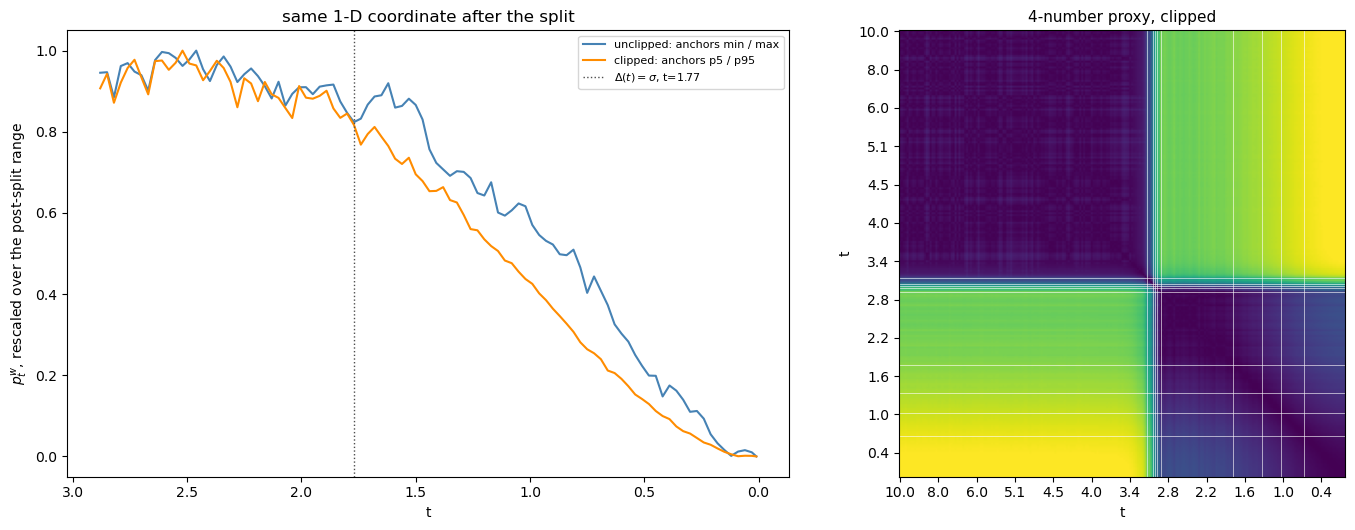

In [8]:
P_clip, pw_clip, _ = proxy_sagd(raw["lc_w_med"], raw["lc_b_med"], raw["lc_p5"], raw["lc_p95"])
print(f"clipped: corr(proxy, SAGD) all {compare(raw_clipped['S'], P_clip, np.ones_like(post)):.4f}, "
      f"after the split {compare(raw_clipped['S'], P_clip, post):.5f}")


def rescale(x, mask):
    return (x - x[mask].min()) / (x[mask].max() - x[mask].min())


fig, axes = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
ax.plot(ts[post], rescale(pw_raw, post)[post], color="steelblue", label="unclipped: anchors min / max")
ax.plot(ts[post], rescale(pw_clip, post)[post], color="darkorange", label="clipped: anchors p5 / p95")
mark_times(ax, markers[1:])
ax.invert_xaxis()
ax.set_xlabel("t")
ax.set_ylabel(r"$p^w_t$, rescaled over the post-split range")
ax.set_title("same 1-D coordinate after the split")
ax.legend(fontsize=8)
draw_heatmap(axes[1], P_clip, "4-number proxy, clipped", raw_clipped["bp"])
fig.tight_layout()
fig.savefig(FIGS / "second_phase_clipped.png", dpi=150, bbox_inches="tight")
plt.show()

## Conclusions

* **The second phase is a plateau in one number.** After the kNN graph splits, the normalized
  CTD distribution is fully determined by where the between-cluster spike sits relative to a
  fixed within-cluster distribution. SAGD between two post-split snapshots is, to correlation
  0.9999, the 1-D distance between those spike positions.
* **That position is set by one edge.** Between-cluster commute times run in series through
  the single MST bridge: $\mathrm{CTD}_b/\mathrm{vol} = R_{\text{in}} + \exp(r_b^2/2\sigma^2)$ with
  $R_{\text{in}} \approx 0.9$ constant. The Euclidean gap feeds into the CTD only through the
  bridge length $r_b$, which is an extreme-value statistic (the closest cross-cluster pair), not
  the mean distance.
* **Step → plateau → runaway** is the shape of the map from $r_b$ to the spike position:
  1. *step at the split*: the cut conductance falls from hundreds of parallel edges to one
     edge, while the total within-cluster resistance stays small;
  2. *plateau* while $r_b \approx \sigma$: the bridge resistance $\approx e^{1/2}$ is comparable to
     $R_{\text{in}}$, and the clusters have not yet moved apart by a kernel width;
  3. *runaway* once $\Delta(t) > \sigma$: $\log \mathrm{CTD}_b \approx \Delta(t)^2/2\sigma^2 \propto e^{-2t}$.
     The predicted crossover is $t_\times = \ln(2\mu\sqrt D/\sigma) \approx 1.77$; the DP places the
     boundary at 1.65 (N = 4000, unclipped), 1.44 (N = 1000, unclipped) and 1.74 (N = 1000, clipped).
* **What this says about the method.** The middle phase comes from the graph construction (one
  MST bridge + a Gaussian kernel with a global $\sigma$) together with min-max normalization. It is
  not a change in the within-cluster geometry, which stays frozen from $t = 10$ to $t = 0$. With
  a different connectivity rule, such as injected random edges, the cut would not shrink to a
  single edge and the profile would change. The `inject_edges` runs would test this. Since the
  within-cluster CTD distribution never changes, any post-split SAGD signal is a signal about the
  cut alone.